In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn xgboost

Note: you may need to restart the kernel to use updated packages.


In [2]:
import re
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score
)

from xgboost import XGBClassifier

sns.set_theme(style="whitegrid")

In [4]:
df = pd.read_csv(
    "SMSSpamCollection",
    sep="\t",
    header=None,
    names=["Label", "Message"],
    encoding="utf-8"
)

df.head()

,Label,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [5]:
print("Dataset shape:", df.shape)

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nClass counts:")
print(df["Label"].value_counts())

Dataset shape: (5572, 2)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   Label    5572 non-null   object
 1   Message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB

Missing values:
Label      0
Message    0
dtype: int64

Class counts:
Label
ham     4825
spam     747
Name: count, dtype: int64


In [6]:
df.dropna(subset=["Label", "Message"], inplace=True)

df["Label"] = df["Label"].str.strip().str.lower()

df = df[df["Label"].isin(["ham", "spam"])]

df.drop_duplicates(subset=["Label", "Message"], inplace=True)

df.reset_index(drop=True, inplace=True)

print("Cleaned dataset shape:", df.shape)
print(df["Label"].value_counts())

Cleaned dataset shape: (5169, 2)
Label
ham     4516
spam     653
Name: count, dtype: int64


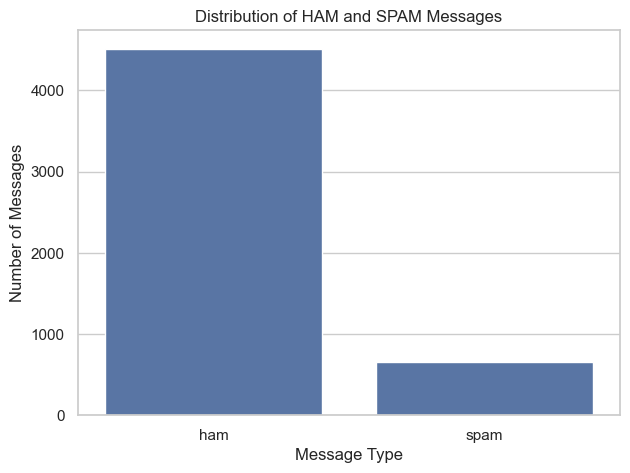

In [7]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Label", order=["ham", "spam"])

plt.title("Distribution of HAM and SPAM Messages")
plt.xlabel("Message Type")
plt.ylabel("Number of Messages")

plt.show()

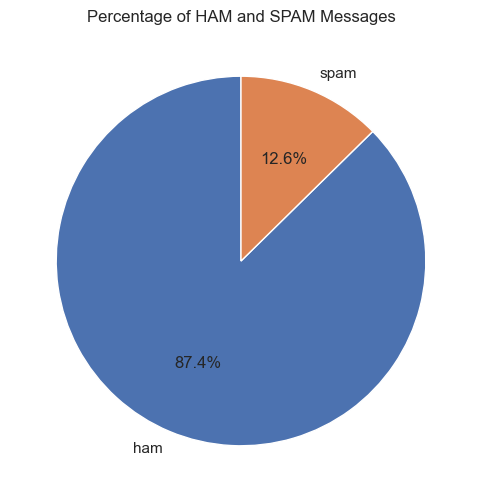

In [8]:
df["Label"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90,
    figsize=(6, 6)
)

plt.title("Percentage of HAM and SPAM Messages")
plt.ylabel("")

plt.show()

In [9]:
df["Character_Count"] = df["Message"].str.len()
df["Word_Count"] = df["Message"].str.split().str.len()

df.head()

,Label,Message,Character_Count,Word_Count
0,ham,"Go until jurong point, crazy.. Available only ...",111,20
1,ham,Ok lar... Joking wif u oni...,29,6
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155,28
3,ham,U dun say so early hor... U c already then say...,49,11
4,ham,"Nah I don't think he goes to usf, he lives aro...",61,13


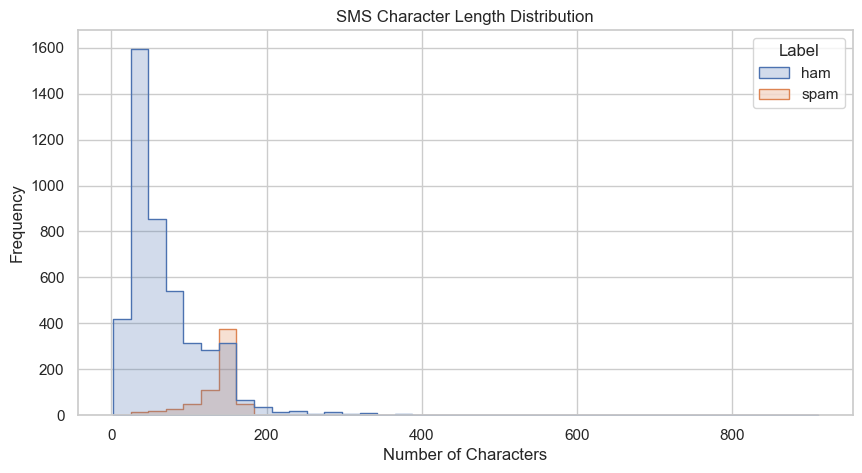

In [10]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Character_Count",
    hue="Label",
    bins=40,
    element="step"
)

plt.title("SMS Character Length Distribution")
plt.xlabel("Number of Characters")
plt.ylabel("Frequency")

plt.show()

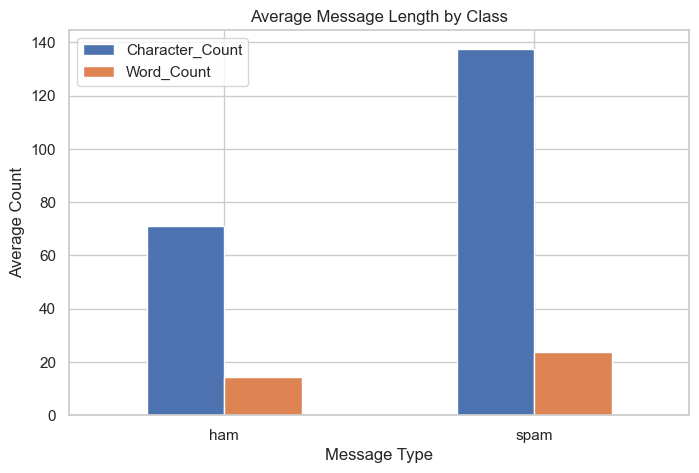

In [11]:
length_means = df.groupby("Label")[
    ["Character_Count", "Word_Count"]
].mean()

length_means.plot(kind="bar", figsize=(8, 5))

plt.title("Average Message Length by Class")
plt.xlabel("Message Type")
plt.ylabel("Average Count")
plt.xticks(rotation=0)

plt.show()

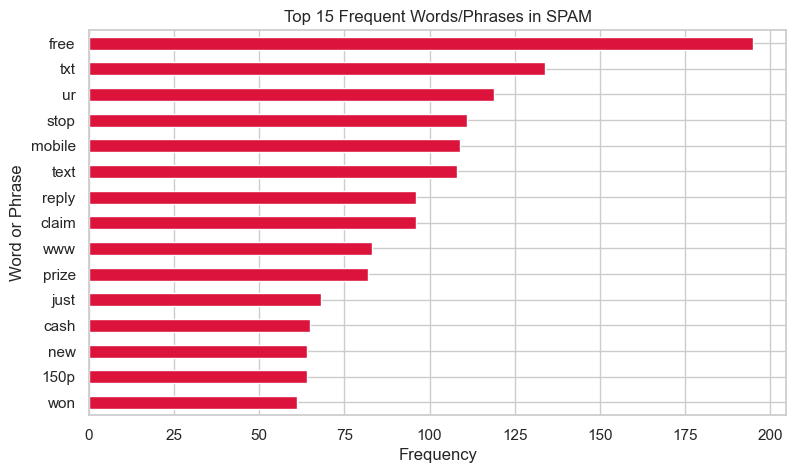

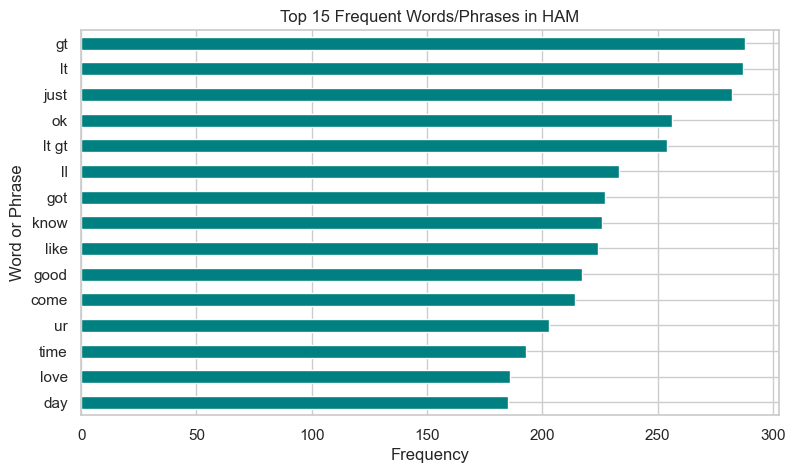

In [12]:
def plot_frequent_words(label, title, color):
    messages = df.loc[df["Label"] == label, "Message"]

    vectorizer = CountVectorizer(
        stop_words="english",
        ngram_range=(1, 2),
        max_features=15
    )

    word_matrix = vectorizer.fit_transform(messages)

    word_counts = np.asarray(
        word_matrix.sum(axis=0)
    ).ravel()

    words = vectorizer.get_feature_names_out()

    top_words = pd.Series(
        word_counts,
        index=words
    ).sort_values().tail(15)

    plt.figure(figsize=(9, 5))
    top_words.plot(kind="barh", color=color)

    plt.title(title)
    plt.xlabel("Frequency")
    plt.ylabel("Word or Phrase")

    plt.show()


plot_frequent_words(
    "spam",
    "Top 15 Frequent Words/Phrases in SPAM",
    "crimson"
)

plot_frequent_words(
    "ham",
    "Top 15 Frequent Words/Phrases in HAM",
    "teal"
)

In [14]:
def clean_sms(text):
    text = str(text).lower()

    # Replace web links with a common token
    text = re.sub(
        r"https?://\S+|www\.\S+",
        " urltoken ",
        text
    )

    # Replace currency symbols with a common token
    text = re.sub(
        r"[$£€₹]",
        " currencytoken ",
        text
    )

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


df["Clean_Message"] = df["Message"].apply(clean_sms)

X = df["Clean_Message"]
y = df["Label"].map({"ham": 0, "spam": 1})

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (5169,)
y shape: (5169,)


In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 4135
Testing records: 1034


In [16]:
tfidf = TfidfVectorizer(
    max_features=1500,
    ngram_range=(1, 2),
    dtype=np.float32
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training feature shape:", X_train_tfidf.shape)
print("Testing feature shape:", X_test_tfidf.shape)

Training feature shape: (4135, 1500)
Testing feature shape: (1034, 1500)


In [17]:
# Convert sparse TF-IDF features to dense arrays for
# scikit-learn's Gradient Boosting implementation.
# With 1,500 features, this should be manageable for
# this dataset on a typical student laptop.

X_train_dense = X_train_tfidf.toarray()
X_test_dense = X_test_tfidf.toarray()

In [18]:
# 1. Single Decision Tree
dt_model = DecisionTreeClassifier(
    max_depth=20,
    random_state=42
)

# 2. Random Forest: bagging + random feature subsets
rf_model = RandomForestClassifier(
    n_estimators=150,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

# 3. AdaBoost: weak Decision Tree learners
weak_tree = DecisionTreeClassifier(max_depth=1)

try:
    ada_model = AdaBoostClassifier(
        estimator=weak_tree,
        n_estimators=100,
        learning_rate=0.5,
        random_state=42
    )
except TypeError:
    # Compatibility with older scikit-learn versions
    ada_model = AdaBoostClassifier(
        base_estimator=weak_tree,
        n_estimators=100,
        learning_rate=0.5,
        random_state=42
    )

# 4. Gradient Boosting
gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=2,
    max_features=0.3,
    random_state=42
)

# 5. XGBoost
xgb_model = XGBClassifier(
    n_estimators=150,
    max_depth=4,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

models = {
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "AdaBoost": ada_model,
    "Gradient Boosting": gb_model,
    "XGBoost": xgb_model
}

In [19]:
trained_models = {}
predictions = {}
probabilities = {}
results = []

for name, model in models.items():

    print("Training:", name)

    # Gradient Boosting requires dense input
    if name == "Gradient Boosting":
        Xtr = X_train_dense
        Xte = X_test_dense
    else:
        Xtr = X_train_tfidf
        Xte = X_test_tfidf

    start_time = time.time()

    model.fit(Xtr, y_train)

    training_time = time.time() - start_time

    y_pred = model.predict(Xte)
    y_prob = model.predict_proba(Xte)[:, 1]

    trained_models[name] = model
    predictions[name] = y_pred
    probabilities[name] = y_prob

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Spam Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Spam Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "Spam F1": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob),
        "Training Time (seconds)": training_time
    })

    print("Completed:", name, "\n")

Training: Decision Tree
Completed: Decision Tree 

Training: Random Forest
Completed: Random Forest 

Training: AdaBoost
Completed: AdaBoost 

Training: Gradient Boosting
Completed: Gradient Boosting 

Training: XGBoost
Completed: XGBoost 



In [20]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Spam F1",
    ascending=False
)

display(results_df.round(3))

,Model,Accuracy,Spam Precision,Spam Recall,Spam F1,ROC-AUC,PR-AUC,Training Time (seconds)
1,Random Forest,0.981,0.983,0.863,0.919,0.991,0.967,0.528
4,XGBoost,0.979,0.982,0.847,0.910,0.976,0.946,0.664
0,Decision Tree,0.967,0.882,0.855,0.868,0.904,0.772,0.169
3,Gradient Boosting,0.963,0.979,0.725,0.833,0.963,0.919,3.779
2,AdaBoost,0.938,1.000,0.511,0.677,0.940,0.862,1.228


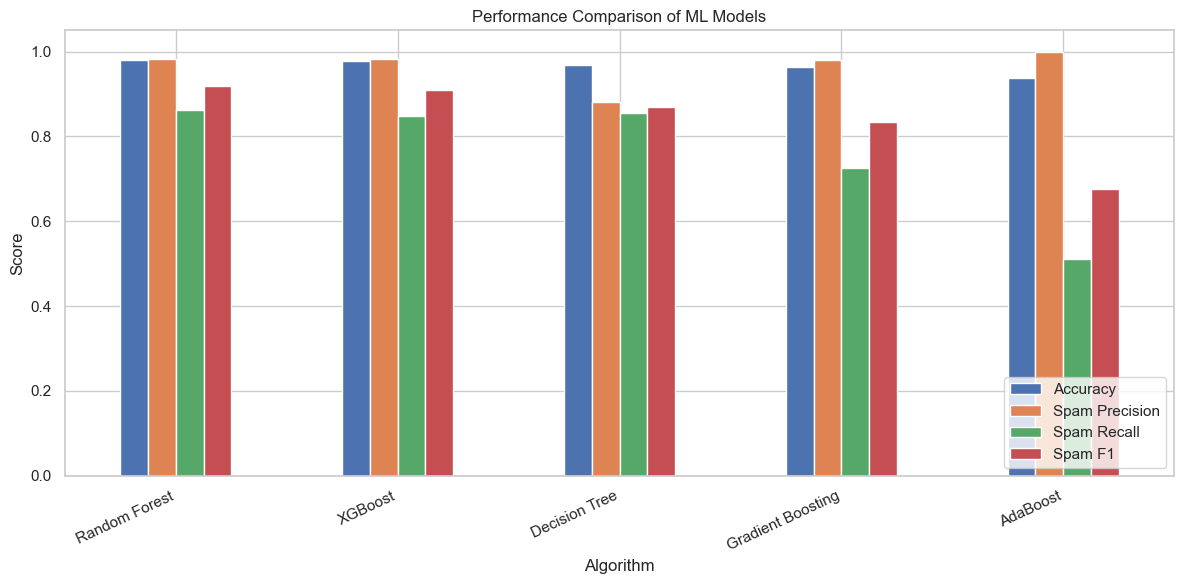

In [21]:
metrics = [
    "Accuracy",
    "Spam Precision",
    "Spam Recall",
    "Spam F1"
]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Performance Comparison of ML Models")
plt.ylabel("Score")
plt.xlabel("Algorithm")
plt.ylim(0, 1.05)
plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower right")

plt.tight_layout()
plt.show()

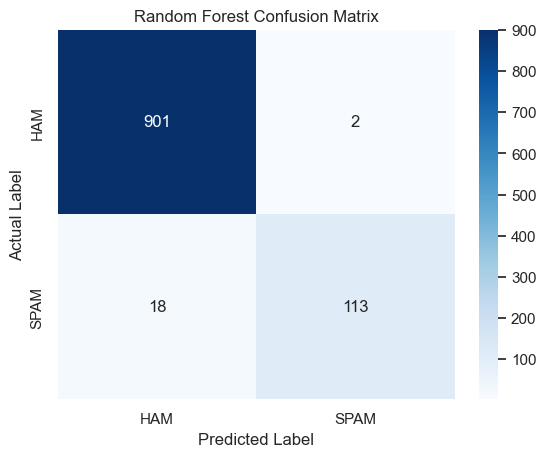

In [22]:
rf_predictions = predictions["Random Forest"]

cm = confusion_matrix(
    y_test,
    rf_predictions,
    labels=[0, 1]
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["HAM", "SPAM"],
    yticklabels=["HAM", "SPAM"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

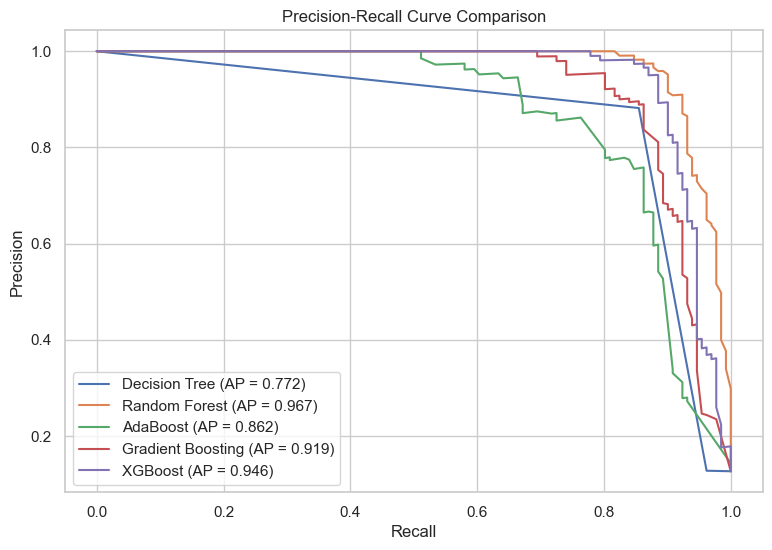

In [23]:
plt.figure(figsize=(9, 6))

for name, y_prob in probabilities.items():

    precision, recall, _ = precision_recall_curve(
        y_test,
        y_prob
    )

    ap = average_precision_score(y_test, y_prob)

    plt.plot(
        recall,
        precision,
        label=f"{name} (AP = {ap:.3f})"
    )

plt.title("Precision-Recall Curve Comparison")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.show()

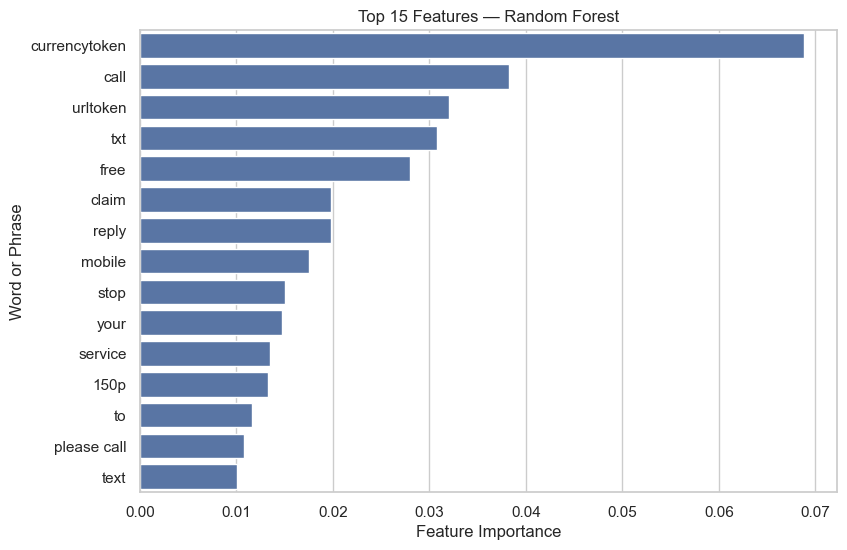

In [24]:
rf = trained_models["Random Forest"]

feature_names = tfidf.get_feature_names_out()
importances = rf.feature_importances_

importance_df = pd.DataFrame({
    "Word": feature_names,
    "Importance": importances
})

top_features = importance_df.nlargest(15, "Importance")

plt.figure(figsize=(9, 6))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Word"
)

plt.title("Top 15 Features — Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Word or Phrase")

plt.show()

In [25]:
message = input("Enter an SMS message: ")

cleaned_message = clean_sms(message)

message_tfidf = tfidf.transform([cleaned_message])

rf = trained_models["Random Forest"]

prediction = rf.predict(message_tfidf)[0]
spam_score = rf.predict_proba(message_tfidf)[0, 1]

if prediction == 1:
    print("\nPrediction: SPAM")
else:
    print("\nPrediction: HAM")

print(f"Estimated spam score: {spam_score * 100:.2f}%")

Enter an SMS message:  Netflix: AJ, your subscription has expired. Renew now for just $1 a month: 62jjsm4.eeaar.com



Prediction: SPAM
Estimated spam score: 57.33%
